# MEMC exercise 1 – Introduction to Monte Carlo

---

In this notebook you see the whole Monte Carlo method on the three simplest problems there are:

- estimating $\pi$ (hit-or-miss)
- estimating $\pi$ from Buffon's needle
- estimating the integral $\int_0^1 e^{-x^2}\,dx$

and above all you take away one rule that holds throughout the course:

> **The error of a Monte Carlo estimate falls off like $1/\sqrt{N}$.** Want a result ten times as
> accurate? You need a hundred times as many points.

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def estimate(sampler, n):
    '''Plain Monte Carlo: the average of n calls of the generator and its standard error sigma/sqrt(n).'''
    s = s2 = 0.0
    for _ in range(n):
        x = sampler()
        s += x
        s2 += x * x
    mean = s / n
    var = max(s2 / n - mean * mean, 0.0)
    return mean, math.sqrt(var / n)


def check(name, mean, se, exact, k=5):
    '''Prints the estimate and verifies it lies within k standard errors of the exact value.'''
    print(f"{name}: {mean:.5f} +- {se:.5f}  (exact {exact:.5f})")
    assert abs(mean - exact) <= k * se, name

The function `estimate` takes a **generator** (a function of no arguments that returns one random
sample per call) and a number of samples $n$. It returns the average and the standard error
$\sigma/\sqrt{n}$, where $\sigma$ is estimated from the samples themselves. We use `check` to
verify results against an exact value.

## The main idea

We want to compute some quantity $\theta$. We find a random variable $X$ such that $E X = \theta$,
and then

$$\theta = E X \approx \bar X_N = \frac{1}{N}\sum_{i=1}^N X_i, \qquad \text{error} \approx \frac{\sigma}{\sqrt{N}}.$$

By the CLT the exact value lies, with probability $\approx 95\,\%$, in the confidence interval
$\bar X_N \pm 2\,\sigma/\sqrt{N}$. The whole art of Monte Carlo is in coming up with a suitable $X$.

## 1. Estimating $\pi$ by hit-or-miss

A point $(X, Y)$ distributed uniformly in the unit square $[0,1]^2$ falls into the quarter circle
$x^2 + y^2 \le 1$ with a probability equal to the ratio of the areas:

$$P(X^2 + Y^2 \le 1) = \frac{\pi/4}{1} = \frac{\pi}{4}.$$

So we take $X_i = 4\cdot\mathbf 1[\text{the point fell into the quarter circle}]$. Then
$E X_i = \pi$, and $X_i$ takes only the values $0$ and $4$.

In [2]:
def pi_hit():
    x = random.random()
    y = random.random()
    return 4.0 if x * x + y * y <= 1 else 0.0


print(f"{'N':>9s} {'pi est.':>10s} {'|error|':>10s} {'std err':>10s}  error within 2 std errs?")
for e in range(1, 7):
    n = 10 ** e
    m, se = estimate(pi_hit, n)
    print(f"{n:9,d} {m:10.5f} {abs(m - math.pi):10.5f} {se:10.5f}  {'yes' if abs(m - math.pi) <= 2 * se else 'no'}".replace(",", " "))

m, se = estimate(pi_hit, 1_000_000)
check("pi", m, se, math.pi)

        N    pi est.    |error|    std err  error within 2 std errs?
       10    3.60000    0.45841    0.37947  yes
      100    3.08000    0.06159    0.16833  yes
    1 000    3.14000    0.00159    0.05197  yes
   10 000    3.14560    0.00401    0.01639  yes
  100 000    3.13844    0.00315    0.00520  yes
1 000 000    3.14114    0.00045    0.00164  yes


pi: 3.14337 +- 0.00164  (exact 3.14159)


Before we look at the numbers, **a picture of what we are doing**: on the left the points in the
unit square, in green the ones that fell into the quarter circle. The fraction of green ones is
$\pi/4$. On the right the running estimate of $\pi$ from one long run: as $N$ grows it settles down
and the band $\pm 2\,\sigma/\sqrt{N}$ (the confidence interval) narrows.

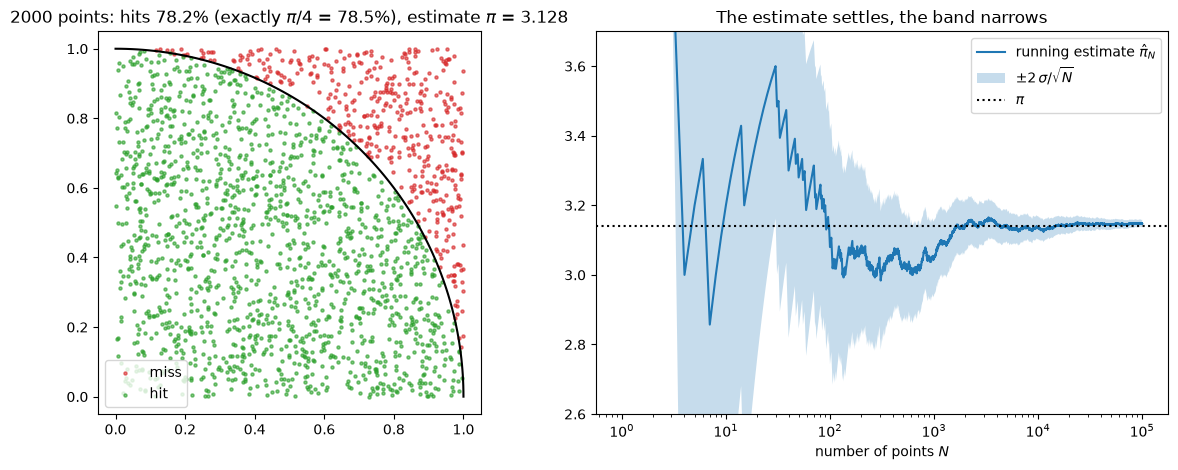

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# left: 2000 points in the square
M_ = 2000
inside, outside = [], []
for _ in range(M_):
    x, y = random.random(), random.random()
    (inside if x * x + y * y <= 1 else outside).append((x, y))
ax = axes[0]
ax.scatter(*zip(*outside), s=5, c="tab:red", alpha=0.6, label="miss")
ax.scatter(*zip(*inside), s=5, c="tab:green", alpha=0.6, label="hit")
ax.plot([math.cos(t / 100 * math.pi / 2) for t in range(101)], [math.sin(t / 100 * math.pi / 2) for t in range(101)], "k")
ax.set_aspect("equal")
ax.set_title(f"{M_} points: hits {len(inside) / M_:.1%} (exactly $\\pi/4$ = {math.pi / 4:.1%}), estimate $\\pi$ = {4 * len(inside) / M_:.3f}")
ax.legend(loc="lower left")

# right: running estimate with a +- 2 std error band
N_ = 100_000
s = 0
run, band = [], []
for i in range(1, N_ + 1):
    x, y = random.random(), random.random()
    s += x * x + y * y <= 1
    p = s / i
    run.append(4 * p)
    band.append(4 * 2 * math.sqrt(max(p * (1 - p), 1e-12) / i))
idx = list(range(1, N_ + 1))
axes[1].semilogx(idx, run, label="running estimate $\\hat\\pi_N$")
axes[1].fill_between(idx, [b - w for b, w in zip(run, band)], [b + w for b, w in zip(run, band)], alpha=0.25, label="$\\pm 2\\,\\sigma/\\sqrt{N}$")
axes[1].axhline(math.pi, color="k", ls=":", label="$\\pi$")
axes[1].set_ylim(2.6, 3.7)
axes[1].set_xlabel("number of points $N$")
axes[1].set_title("The estimate settles, the band narrows")
axes[1].legend()
plt.tight_layout()
plt.show()

The error falls off slowly with $N$. Let us show that on a plot: for each $N$ we repeat the
estimate 20 times and plot the mean absolute error on log axes. A straight line of slope $-1/2$
means an error $\propto 1/\sqrt{N}$.

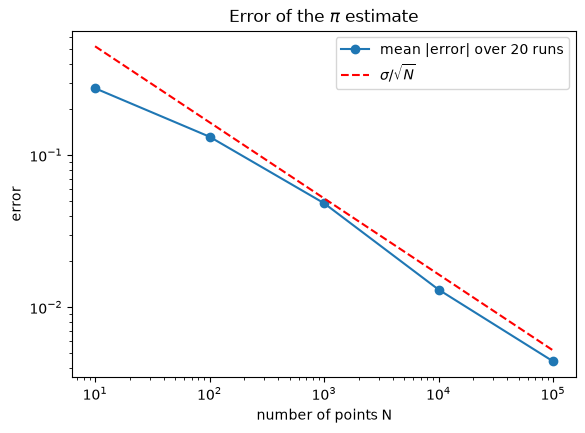

sigma = 1.6422; for an error of 0.001 (2 std errors) we need N = 10 787 065


In [4]:
sigma_pi = 4 * math.sqrt(math.pi / 4 * (1 - math.pi / 4))  # the exact sigma of the variable X_i

Ns = [10 ** e for e in range(1, 6)]
repeats = 20
mean_err = []
for n in Ns:
    errs = [abs(estimate(pi_hit, n)[0] - math.pi) for _ in range(repeats)]
    mean_err.append(sum(errs) / repeats)

plt.figure(figsize=(6.5, 4.5))
plt.loglog(Ns, mean_err, "o-", label="mean |error| over 20 runs")
plt.loglog(Ns, [sigma_pi / math.sqrt(n) for n in Ns], "r--", label=r"$\sigma/\sqrt{N}$")
plt.xlabel("number of points N")
plt.ylabel("error")
plt.title(r"Error of the $\pi$ estimate")
plt.legend()
plt.show()

print(f"sigma = {sigma_pi:.4f}; for an error of 0.001 (2 std errors) we need N = {(2 * sigma_pi / 0.001) ** 2:,.0f}".replace(",", " "))

The measured error runs parallel to the line $\sigma/\sqrt{N}$, just a little below it: the mean
*absolute* error is roughly $0.8\,\sigma/\sqrt{N}$. What matters is the slope.

Three correct digits of $\pi$ cost roughly **ten million points**. So for estimating $\pi$, Monte
Carlo really is a bad choice. The strength of the method lies elsewhere: the error $\sim 1/\sqrt{N}$
**does not depend on the dimension** of the problem (see section 5).

## 2. Buffon's needle

There are parallel lines on the floor at a spacing of $D$. We throw a needle of length $L \le D$.
Write:

- $x \in [0, D/2]$ for the distance of the needle's centre from the nearest line,
- $\theta \in [0, \pi/2]$ for the angle between the needle and the lines.

The needle crosses a line when $x \le \tfrac{L}{2}\sin\theta$. The pair $(x, \theta)$ is uniform on
the rectangle $[0, D/2]\times[0, \pi/2]$, so

$$p = P(\text{crosses}) = \frac{1}{\frac D2\cdot\frac\pi2}\int_0^{\pi/2}\frac L2\sin\theta\,d\theta = \frac{2L}{\pi D}
\quad\Longrightarrow\quad \pi = \frac{2L}{D\,p}.$$

We estimate $p$ as the fraction of hits and substitute. The standard error of $\pi$ follows from the
standard error of $p$: the relative error carries over,
$\operatorname{se}(\hat\pi) \approx \hat\pi\cdot\operatorname{se}(\hat p)/\hat p$ (the so-called
delta method).

What it looks like: on the left the needles on the floor (in red the ones that cross a line), on
the right the **space of possibilities** $(\theta, x)$ with the region $x \le \tfrac L2\sin\theta$.
The probability of crossing is the ratio of the area under the curve to the area of the whole
rectangle — exactly the same thing as with the quarter circle.

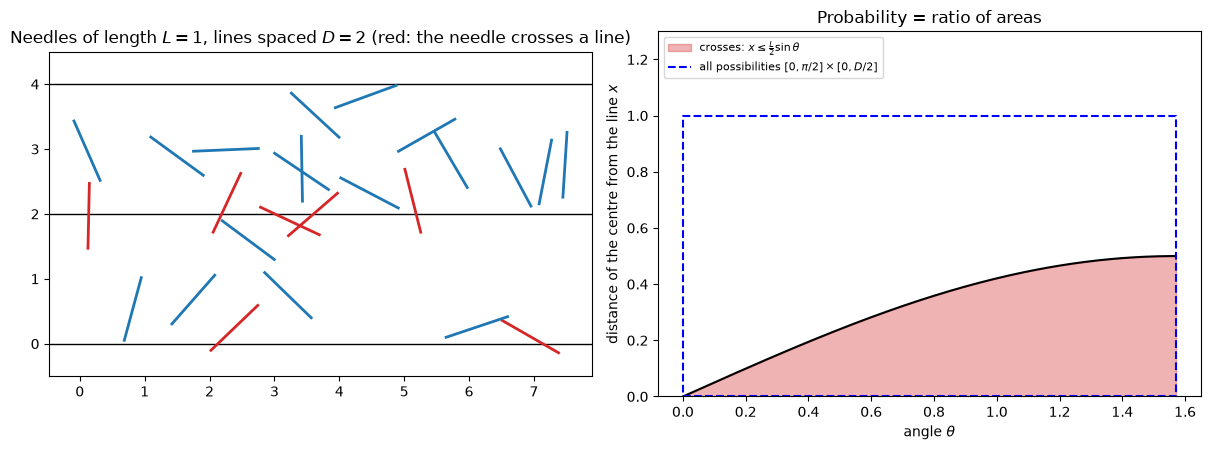

In [5]:
L_, D_ = 1.0, 2.0
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

# left: 25 needles between the lines
ax = axes[0]
for k in range(-1, 3):
    ax.axhline(k * D_, color="k", lw=1)
for _ in range(25):
    cx, cy = random.random() * 8, random.random() * 2 * D_
    th = random.random() * math.pi
    dist = min(cy % D_, D_ - cy % D_)
    crosses = dist <= L_ / 2 * abs(math.sin(th))
    dx, dy = L_ / 2 * math.cos(th), L_ / 2 * math.sin(th)
    ax.plot([cx - dx, cx + dx], [cy - dy, cy + dy], color="tab:red" if crosses else "tab:blue", lw=2)
ax.set_aspect("equal")
ax.set_ylim(-0.5, 2 * D_ + 0.5)
ax.set_title("Needles of length $L = 1$, lines spaced $D = 2$ (red: the needle crosses a line)")

# right: the space (theta, x) and the hit region
ax = axes[1]
ths = [i / 200 * math.pi / 2 for i in range(201)]
ax.fill_between(ths, [L_ / 2 * math.sin(t) for t in ths], color="tab:red", alpha=0.35, label="crosses: $x \\leq \\frac{L}{2}\\sin\\theta$")
ax.plot(ths, [L_ / 2 * math.sin(t) for t in ths], "k")
ax.plot([0, math.pi / 2, math.pi / 2, 0, 0], [0, 0, D_ / 2, D_ / 2, 0], "b--", label="all possibilities $[0,\\pi/2]\\times[0,D/2]$")
ax.set_xlabel(r"angle $\theta$")
ax.set_ylabel("distance of the centre from the line $x$")
ax.set_title("Probability = ratio of areas")
ax.set_ylim(0, 1.3)
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

In [6]:
def buffon_hit(L=1.0, D=2.0):
    x = random.random() * D / 2             # distance of the needle's centre from the nearest line
    theta = random.random() * math.pi / 2   # angle of the needle (careful: we are using pi!)
    return 1.0 if x <= L * math.sin(theta) / 2 else 0.0


def buffon_pi(n, L=1.0, D=2.0):
    p, se = estimate(lambda: buffon_hit(L, D), n)
    pi_hat = 2 * L / (D * p)
    return pi_hat, pi_hat * se / p


print(f"{'N':>9s} {'pi est.':>10s} {'|error|':>10s} {'std err':>10s}")
for e in range(2, 7):
    n = 10 ** e
    m, se = buffon_pi(n)
    print(f"{n:9,d} {m:10.5f} {abs(m - math.pi):10.5f} {se:10.5f}".replace(",", " "))

        N    pi est.    |error|    std err
      100    2.94118    0.20042    0.40978
    1 000    3.31126    0.16967    0.15919
   10 000    3.12598    0.01562    0.04558
  100 000    3.15000    0.00841    0.01461


1 000 000    3.14419    0.00260    0.00460


With $L = 1$, $D = 2$ we have $p = 1/\pi \approx 0.318$, and the convergence is even slower than
with the previous method.

> **An honest note:** our simulator generates the angle $\theta$ using `math.pi`, so "computing
> $\pi$ by means of $\pi$" is really cheating. A real experiment would not need the angle at all.
> What we are after here is the exercise in deriving the probability, and the demonstration that the
> same constant can be obtained from a different problem.

## 3. An integral as an expectation

If $\gamma \sim R(a, b)$ is uniform on $[a, b]$, then
$E f(\gamma) = \frac{1}{b-a}\int_a^b f(x)\,dx$. Hence

$$I = \int_a^b f(x)\,dx = (b - a)\,E f(\gamma) \approx (b-a)\,\frac{1}{N}\sum_{i=1}^N f(\gamma_i),
\qquad \operatorname{se} = (b-a)\,\frac{\sigma_f}{\sqrt{N}}.$$

We try it on $f(x) = e^{-x^2}$ over $[0, 1]$. The exact value is known from the relation to the
error function: $I = \tfrac{\sqrt\pi}{2}\operatorname{erf}(1)$.

In [7]:
def mc_integral(f, a=0.0, b=1.0, n=10_000):
    '''Estimate of the integral of f over [a, b] as (b - a) * average of f(γ), γ ~ R(a, b). Returns (estimate, std err).'''
    m, se = estimate(lambda: f(a + (b - a) * random.random()), n)
    return (b - a) * m, (b - a) * se


f = lambda x: math.exp(-x * x)
exact = math.sqrt(math.pi) / 2 * math.erf(1)

print(f"exact I = {exact:.6f}")
print(f"{'N':>9s} {'estimate':>10s} {'|error|':>10s} {'std err':>10s}")
for e in range(1, 7):
    n = 10 ** e
    m, se = mc_integral(f, 0.0, 1.0, n)
    print(f"{n:9,d} {m:10.6f} {abs(m - exact):10.6f} {se:10.6f}".replace(",", " "))

m, se = mc_integral(f, 0.0, 1.0, 1_000_000)
check("integral", m, se, exact)

exact I = 0.746824
        N   estimate    |error|    std err
       10   0.821190   0.074366   0.053728
      100   0.759936   0.013112   0.021560
    1 000   0.753996   0.007172   0.006343
   10 000   0.747754   0.000930   0.002013
  100 000   0.747297   0.000473   0.000637


1 000 000   0.746862   0.000037   0.000201


integral: 0.74638 +- 0.00020  (exact 0.74682)


### Two ways to estimate the same thing

The integral can also be estimated by **hit-or-miss**, as with $\pi$: take a point $(x, y)$ in the
rectangle $[a,b]\times[0,C]$ and the fraction of those that fall below the graph, multiplied by the
area of the rectangle $C(b-a)$. Which way is more accurate at the same $N$?

A picture of both ways side by side: **on the left** the average of the function values (at $N$
random points we measure the height of the graph, and the average height times the width is the
estimate of the area), **on the right** hit-or-miss (random points in the rectangle, the fraction
below the graph times the area).

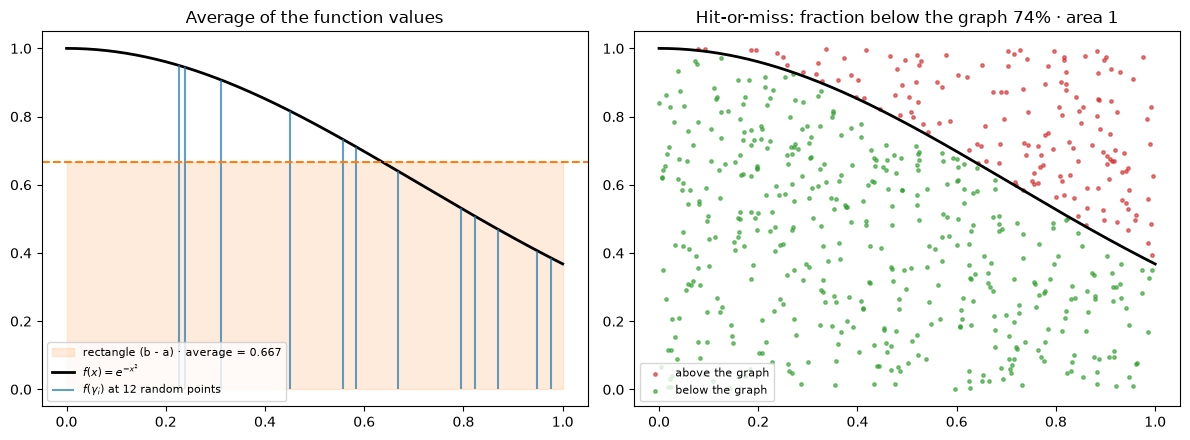

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
grid = [i / 200 for i in range(201)]
ax = axes[0]
us = [random.random() for _ in range(12)]
height = sum(f(u) for u in us) / len(us)
ax.fill_between(grid, [height] * len(grid), alpha=0.15, color="tab:orange", label=f"rectangle (b - a) · average = {height:.3f}")
ax.plot(grid, [f(x) for x in grid], "k", lw=2, label="$f(x) = e^{-x^2}$")
ax.vlines(us, 0, [f(u) for u in us], color="tab:blue", alpha=0.7, label="$f(\\gamma_i)$ at 12 random points")
ax.axhline(height, color="tab:orange", ls="--")
ax.set_title("Average of the function values")
ax.legend(loc="lower left", fontsize=8)

ax = axes[1]
below, above = [], []
for _ in range(600):
    x, y = random.random(), random.random()
    (below if y < f(x) else above).append((x, y))
ax.scatter(*zip(*above), s=6, c="tab:red", alpha=0.6, label="above the graph")
ax.scatter(*zip(*below), s=6, c="tab:green", alpha=0.6, label="below the graph")
ax.plot(grid, [f(x) for x in grid], "k", lw=2)
ax.set_title(f"Hit-or-miss: fraction below the graph {len(below) / 600:.0%} · area 1")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

In [9]:
def integral_hit_or_miss(f, C, a=0.0, b=1.0, n=10_000):
    '''Hit-or-miss: the fraction of points below the graph of f in the rectangle [a, b] x [0, C], times its area.'''
    area = C * (b - a)
    m, se = estimate(lambda: 1.0 if C * random.random() < f(a + (b - a) * random.random()) else 0.0, n)
    return area * m, area * se


n = 100_000
m1, se1 = mc_integral(f, 0.0, 1.0, n)
m2, se2 = integral_hit_or_miss(f, 1.0, 0.0, 1.0, n)
print(f"average of f(γ):   {m1:.6f} +- {se1:.6f}")
print(f"hit-or-miss:       {m2:.6f} +- {se2:.6f}")
print(f"ratio of errors = {se2 / se1:.2f}, so hit-or-miss needs about {(se2 / se1) ** 2:.1f}x more points")

average of f(γ):   0.746570 +- 0.000636
hit-or-miss:       0.745340 +- 0.001378
ratio of errors = 2.16, so hit-or-miss needs about 4.7x more points


The average of the function values has the smaller variance, because every point contributes a
**value** $f(\gamma_i)$, whereas hit-or-miss reduces it to a mere yes/no. We develop this idea
(variance reduction) in exercise 7.

## 4. How many points do I need?

We want an error of at most $\delta$ at a confidence level of 95 %. From
$k_\alpha\,\sigma/\sqrt{N} \le \delta$ we get

$$N \ge \left(\frac{k_\alpha\,\sigma}{\delta}\right)^2, \qquad k_\alpha \approx 1.96.$$

The snag: we do not know $\sigma$. The solution is a **pilot run**: a small number of samples, from
which we estimate $\sigma \approx \operatorname{se}\cdot\sqrt{n}$, and then work out the $N$ we
need.

In [10]:
n_pilot = 10_000
_, se = mc_integral(f, 0.0, 1.0, n_pilot)
sigma = se * math.sqrt(n_pilot)
print(f"estimate of sigma from the pilot run: {sigma:.4f}\n")

for delta in (1e-2, 1e-3, 1e-4):
    N = math.ceil((1.96 * sigma / delta) ** 2)
    print(f"delta = {delta:g}: N >= {N:,d}".replace(",", " "))

# a check for delta = 1e-3
delta = 1e-3
N = math.ceil((1.96 * sigma / delta) ** 2)
m, _ = mc_integral(f, 0.0, 1.0, N)
print(f"\nactual error for N = {N:,d}: {abs(m - exact):.6f}  (target {delta})".replace(",", " "))

estimate of sigma from the pilot run: 0.2001

delta = 0.01: N >= 1 539
delta = 0.001: N >= 153 834
delta = 0.0001: N >= 15 383 385

actual error for N = 153 834: 0.000636  (target 0.001)


Every extra order of accuracy ($\delta \to \delta/10$) means **100x more points**. Anyone who needs
an accuracy of $10^{-8}$ should reach for a different method (for a one-dimensional integral, the
trapezoidal rule, say). Monte Carlo pays off only once the dimension is large.

## 5. Dimension: the volume of a ball

The volume of the unit ball in $d$ dimensions is known:
$V_d = \dfrac{\pi^{d/2}}{\Gamma(d/2 + 1)}$. We estimate it by hit-or-miss in the cube $[-1, 1]^d$
(of volume $2^d$): $X = 2^d\cdot\mathbf 1[\,\lVert x\rVert \le 1\,]$.

In [11]:
def ball_volume(d):
    '''Generator of the variable X = 2^d * 1[point in the unit ball], the point uniform in [-1, 1]^d.'''
    def sampler():
        r2 = 0.0
        for _ in range(d):
            x = 2 * random.random() - 1
            r2 += x * x
        return 2.0 ** d if r2 <= 1 else 0.0
    return sampler


n = 100_000
print(f"{'d':>2s} {'estimate':>10s} {'exact':>10s} {'std err':>10s} {'rel. error':>11s}")
for d in range(2, 7):
    m, se = estimate(ball_volume(d), n)
    exact_d = math.pi ** (d / 2) / math.gamma(d / 2 + 1)
    assert abs(m - exact_d) <= 5 * se
    print(f"{d:2d} {m:10.4f} {exact_d:10.4f} {se:10.4f} {se / exact_d:10.2%}")

 d   estimate      exact    std err  rel. error
 2     3.1428     3.1416     0.0052      0.17%
 3     4.2020     4.1888     0.0126      0.30%
 4     4.9346     4.9348     0.0234      0.47%
 5     5.2682     5.2638     0.0375      0.71%


 6     5.1616     5.1677     0.0551      1.07%


The same $N = 100\,000$ still gives a usable result in six dimensions. Grid methods (quadratures)
would need $k^d$ points for $k$ points per axis, which grows exponentially with the dimension. With
Monte Carlo it is only the constant $\sigma$ that gets worse with the dimension (here: hits become
rarer and rarer, so the relative error slowly grows), not the exponent $-1/2$.

## Summary

| Concept | What to remember |
|---------|------------------|
| Monte Carlo estimate | $\theta = E X \approx \bar X_N$ |
| Standard error | $\sigma/\sqrt{N}$, with $\sigma$ estimated from the samples (the `estimate` function) |
| Confidence interval | $\bar X_N \pm 2\,\sigma/\sqrt{N}$ (from the CLT, confidence $\approx 95\,\%$) |
| Integral | $\int_a^b f \approx (b-a)\cdot\overline{f(\gamma)}$ |
| Hit-or-miss vs. average | the average of $f(\gamma)$ has a smaller variance than hit-or-miss |
| How many points | $N \ge (k_\alpha\sigma/\delta)^2$; 10x the accuracy = 100x the points |
| Dimension | the error $\propto 1/\sqrt{N}$ does not depend on the dimension, which is why Monte Carlo is used for multidimensional problems |

### Try it yourself

1. Estimate $\int_0^2 \sin(x)\,dx$ (exactly $1 - \cos 2 \approx 1.416$) with `mc_integral` and
   verify it using `check`.
2. In Buffon's problem, change $L$ and $D$ (say $L = D = 1$). How does $p$ change, and how accurate
   is the estimate of $\pi$ at the same $N$?
3. Change `d` in the ball volume to $10$. How many hits out of $100\,000$ do you get, and what is
   the relative error? What does that tell you about the value of hit-or-miss in high dimensions?